In [ ]:
# Set seed for reproducibility
SEED = 42

# Import necessary libraries
import os

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
import torch.nn.functional as F
# from torchsummary import summary
from torch.utils.tensorboard import SummaryWriter
from torch.utils.data import TensorDataset, DataLoader
logs_dir = "tensorboard"
!pkill -f tensorboard
%load_ext tensorboard
!mkdir -p models

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import copy
import shutil
from itertools import product
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split, StratifiedKFold
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mode

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline

PyTorch version: 2.0.1+cu117
Device: cuda


### Import dataset

In [ ]:
X_train = pd.read_csv('pirate_pain_train.csv')
y_train = pd.read_csv('pirate_pain_train_labels.csv')
X_test = pd.read_csv('pirate_pain_test.csv')
X_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105760 entries, 0 to 105759
Data columns (total 40 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   sample_index   105760 non-null  int64  
 1   time           105760 non-null  int64  
 2   pain_survey_1  105760 non-null  int64  
 3   pain_survey_2  105760 non-null  int64  
 4   pain_survey_3  105760 non-null  int64  
 5   pain_survey_4  105760 non-null  int64  
 6   n_legs         105760 non-null  object 
 7   n_hands        105760 non-null  object 
 8   n_eyes         105760 non-null  object 
 9   joint_00       105760 non-null  float64
 10  joint_01       105760 non-null  float64
 11  joint_02       105760 non-null  float64
 12  joint_03       105760 non-null  float64
 13  joint_04       105760 non-null  float64
 14  joint_05       105760 non-null  float64
 15  joint_06       105760 non-null  float64
 16  joint_07       105760 non-null  float64
 17  joint_08       105760 non-nul

## Preprocessing
Based on the evaluation done in the `DataPreprocessing&SimpleModelMaker.ipynb` (look here for further details and graphs) some comulmns are dropped (high correlation or low variance).

In [ ]:
feature = ['n_legs', 'n_hands', 'n_eyes']

# Casting categorical values into numerical
X_train['n_eyes'] = X_train['n_eyes'].replace({'two':1, 'one+eye_patch': 0})
X_train['n_hands'] = X_train['n_hands'].replace({'two':1, 'one+hook_hand': 0})
X_train['n_legs'] = X_train['n_legs'].replace({'two':1, 'one+peg_leg': 0})

X_test['n_eyes'] = X_test['n_eyes'].replace({'two':1, 'one+eye_patch': 0})
X_test['n_hands'] = X_test['n_hands'].replace({'two':1, 'one+hook_hand': 0})
X_test['n_legs'] = X_test['n_legs'].replace({'two':1, 'one+peg_leg': 0})

y_train['label'] = y_train['label'].replace({'no_pain': 0, 'low_pain': 1, 'high_pain': 2})

In [ ]:
# DROP joint_30 (COSTANT VALUE)
columns = ['pain_survey_'+str(i) for i in range(1, 5)] + ['n_legs'] + ['joint_'+str(i) if i > 9 else 'joint_0'+str(i) for i in range(13)]+ ['joint_'+str(j) for j in range(26,30)]

columns.remove('joint_10')
print(columns)
## transform into float 32 for better computation
for col in columns:
    X_train[col] = X_train[col].astype(np.float32)
    X_test[col] = X_test[col].astype(np.float32)

cols_to_drop = [
    'n_hands', 'n_eyes',
    'joint_10', 'joint_13', 'joint_14', 'joint_15', 'joint_16',
    'joint_17', 'joint_18', 'joint_19', 'joint_20', 'joint_21',
    'joint_22', 'joint_23', 'joint_24', 'joint_25', 'joint_30'
]

X_train = X_train.drop(columns=cols_to_drop, errors='ignore')
X_test = X_test.drop(columns=cols_to_drop, errors='ignore')


['pain_survey_1', 'pain_survey_2', 'pain_survey_3', 'pain_survey_4', 'n_legs', 'joint_00', 'joint_01', 'joint_02', 'joint_03', 'joint_04', 'joint_05', 'joint_06', 'joint_07', 'joint_08', 'joint_09', 'joint_11', 'joint_12', 'joint_26', 'joint_27', 'joint_28', 'joint_29']


Refine the `build_sequence` function to let it work also with data without labels (used for the test set)

In [ ]:
def build_sequences(df, columns, y, window=50, stride=5):
    # Sanity check to ensure the window is divisible by the stride
    assert window % stride == 0

    # Initialise lists to store sequences and their corresponding labels
    dataset = []
    labels = []


    # Iterate over unique IDs in the DataFrame
    for id in df['sample_index'].unique():
        # Extract sensor data for the current ID
        temp = df[df['sample_index'] == id][columns].values

        # Retrieve the activity label for the current ID
        if y is not None:
          label = y[y['sample_index'] == id]['label'].values[0]

        # Calculate padding length to ensure full windows
        #padding_len = window - len(temp) % window
        padding_len = (window - len(temp) % window) % window

        # Create zero padding and concatenate with the data
        padding = np.zeros((padding_len, len(columns)), dtype='float32') 
        temp = np.concatenate((temp, padding))

        # Build feature windows and associate them with labels
        idx = 0
        while idx + window <= len(temp):
            dataset.append(temp[idx:idx + window])
            if y is not None:
              labels.append(label)
            idx += stride

    # Convert lists to numpy arrays for further processing
    dataset = np.array(dataset)
    labels = np.array(labels)

    return dataset, labels

In [116]:
def make_loader(ds, batch_size, shuffle, drop_last):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,  # Load 4 batches ahead
    )

In [117]:
def recurrent_summary(model, input_size):
    """
    Custom summary function that emulates torchinfo's output while correctly
    counting parameters for RNN/GRU/LSTM layers.

    This function is designed for models whose direct children are
    nn.Linear, nn.RNN, nn.GRU, or nn.LSTM layers.

    Args:
        model (nn.Module): The model to analyze.
        input_size (tuple): Shape of the input tensor (e.g., (seq_len, features)).
    """

    # Dictionary to store output shapes captured by forward hooks
    output_shapes = {}
    # List to track hook handles for later removal
    hooks = []

    def get_hook(name):
        """Factory function to create a forward hook for a specific module."""
        def hook(module, input, output):
            # Handle RNN layer outputs (returns a tuple)
            if isinstance(output, tuple):
                # output[0]: all hidden states with shape (batch, seq_len, hidden*directions)
                shape1 = list(output[0].shape)
                shape1[0] = -1  # Replace batch dimension with -1

                # output[1]: final hidden state h_n (or tuple (h_n, c_n) for LSTM)
                if isinstance(output[1], tuple):  # LSTM case: (h_n, c_n)
                    shape2 = list(output[1][0].shape)  # Extract h_n only
                else:  # RNN/GRU case: h_n only
                    shape2 = list(output[1].shape)

                # Replace batch dimension (middle position) with -1
                shape2[1] = -1

                output_shapes[name] = f"[{shape1}, {shape2}]"

            # Handle standard layer outputs (e.g., Linear)
            else:
                shape = list(output.shape)
                shape[0] = -1  # Replace batch dimension with -1
                output_shapes[name] = f"{shape}"
        return hook

    # 1. Determine the device where model parameters reside
    try:
        device = next(model.parameters()).device
    except StopIteration:
        device = torch.device("cpu")  # Fallback for models without parameters

    # 2. Create a dummy input tensor with batch_size=1
    dummy_input = torch.randn(1, *input_size).to(device)

    # 3. Register forward hooks on target layers
    # Iterate through direct children of the model (e.g., self.rnn, self.classifier)
    for name, module in model.named_children():
        if isinstance(module, (nn.Linear, nn.RNN, nn.GRU, nn.LSTM)):
            # Register the hook and store its handle for cleanup
            hook_handle = module.register_forward_hook(get_hook(name))
            hooks.append(hook_handle)

    # 4. Execute a dummy forward pass in evaluation mode
    model.eval()
    with torch.no_grad():
        try:
            model(dummy_input)
        except Exception as e:
            print(f"Error during dummy forward pass: {e}")
            # Clean up hooks even if an error occurs
            for h in hooks:
                h.remove()
            return

    # 5. Remove all registered hooks
    for h in hooks:
        h.remove()

    # --- 6. Print the summary table ---

    print("-" * 79)
    # Column headers
    print(f"{'Layer (type)':<25} {'Output Shape':<28} {'Param #':<18}")
    print("=" * 79)

    total_params = 0
    total_trainable_params = 0

    # Iterate through modules again to collect and display parameter information
    for name, module in model.named_children():
        if name in output_shapes:
            # Count total and trainable parameters for this module
            module_params = sum(p.numel() for p in module.parameters())
            trainable_params = sum(p.numel() for p in module.parameters() if p.requires_grad)

            total_params += module_params
            total_trainable_params += trainable_params

            # Format strings for display
            layer_name = f"{name} ({type(module).__name__})"
            output_shape_str = str(output_shapes[name])
            params_str = f"{trainable_params:,}"

            print(f"{layer_name:<25} {output_shape_str:<28} {params_str:<15}")

    print("=" * 79)
    print(f"Total params: {total_params:,}")
    print(f"Trainable params: {total_trainable_params:,}")
    print(f"Non-trainable params: {total_params - total_trainable_params:,}")
    print("-" * 79)

### Architecture

A flexible **RNN-based classifier** (`RNN`, `LSTM`, or `GRU`) that applies an **attention mechanism** over all time steps to produce a context vector for classification.

**Key components:**
- Supports **RNN/LSTM/GRU**, with optional **bidirectional** mode.
- Applies dropout between recurrent layers.
- Uses an **attention network** (`Linear → Tanh → Linear`) to compute attention weights across all RNN outputs.
- Computes a **context vector** as a weighted sum of RNN outputs.
- Final `Linear` layer maps the context vector to class logits.

**Forward pass steps:**
1. Feed sequence through the RNN → `rnn_out`.
2. Compute attention energies from each time step.
3. Apply softmax to obtain attention weights.
4. Compute context vector via weighted sum of `rnn_out`.
5. Classify using a final linear layer.

Returns class **logits** for each sequence.

In [ ]:
class RecurrentClassifierWithAttention(nn.Module):
    """
    Generic RNN classifier (RNN, LSTM, GRU).
    Uses an Attention mechanism over all RNN outputs for classification.
    """
    def __init__(
            self,
            input_size,
            hidden_size,
            num_layers,
            num_classes,
            rnn_type='GRU',
            bidirectional=False,
            dropout_rate=0.2,
            attention_hidden_size = None 
            ):
        super().__init__()

        self.rnn_type = rnn_type
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.bidirectional = bidirectional

        # Map string name to PyTorch RNN class
        rnn_map = {
            'RNN': nn.RNN,
            'LSTM': nn.LSTM,
            'GRU': nn.GRU
        }

        if rnn_type not in rnn_map:
            raise ValueError("rnn_type must be 'RNN', 'LSTM', or 'GRU'")

        rnn_module = rnn_map[rnn_type]

        # Avoid dropout for only one layer network
        dropout_val = dropout_rate if num_layers > 1 else 0

        # Create the recurrent layer
        self.rnn = rnn_module(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,       
            bidirectional=bidirectional,
            dropout=dropout_val
        )

        # Calculate input size for the classifier and attention layers
        if self.bidirectional:
            classifier_input_size = hidden_size * 2 # Concat fwd + bwd
        else:
            classifier_input_size = hidden_size


        if attention_hidden_size is None:
            attention_hidden_size = classifier_input_size 
        
        ## ATTENTION LAYERS 
        self.attention_layers = nn.Sequential(
            nn.Linear(classifier_input_size, attention_hidden_size),
            nn.Tanh(),
            nn.Linear(attention_hidden_size, 1)
        )

        # Final classification layer
        # CHANGED: This layer is the same, but its *input* will be different
        # It now takes the context_vector, which has size classifier_input_size
        self.classifier = nn.Linear(classifier_input_size, num_classes)

    def forward(self, x):
        """
        x shape: (batch_size, seq_length, input_size)
        """

        rnn_out, _ = self.rnn(x)

        ## ATTENTION MECHANISM 
        # Pass all RNN outputs through the attention network
        energy = self.attention_layers(rnn_out)

        # Apply softmax to get weights
        attention_weights = F.softmax(energy, dim=1)

        # Compute weighted average (context vector)
        context_vector = torch.sum(rnn_out * attention_weights, dim=1)

        # Get logits
        logits = self.classifier(context_vector) # CHANGED: Input is context_vector
        return logits

In [ ]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device, l1_lambda=0, l2_lambda=0):
    """
    Perform one complete training epoch through the entire training dataset.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): Lambda for L1 regularization
        l2_lambda (float): Lambda for L2 regularization

    Returns:
        tuple: (average_loss, f1 score) - Training loss and f1 score for this epoch
    """
    model.train()  # Set model to training mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Iterate through training batches
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        # Move data to device (GPU/CPU)
        inputs, targets = inputs.to(device), targets.to(device)

        # Clear gradients from previous step
        optimizer.zero_grad(set_to_none=True)

        # Forward pass with mixed precision (if CUDA available)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            loss = criterion(logits, targets)

            # Add L1 and L2 regularization
            l1_norm = sum(p.abs().sum() for p in model.parameters())
            l2_norm = sum(p.pow(2).sum() for p in model.parameters())
            loss = loss + l1_lambda * l1_norm + l2_lambda * l2_norm


        # Backward pass with gradient scaling
        scaler.scale(loss).backward()

        # ## APPLY CLIPPING
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), 
            max_norm=5.0
        )

        scaler.step(optimizer)
        scaler.update()

        # Accumulate metrics
        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted' ##  weighted for unbalanced class
    )

    return epoch_loss, epoch_f1

In [120]:
def validate_one_epoch(model, val_loader, criterion, device):
    """
    Perform one complete validation epoch through the entire validation dataset.

    Args:
        model (nn.Module): The neural network model to evaluate (must be in eval mode)
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        criterion (nn.Module): Loss function used to calculate validation loss
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)

    Returns:
        tuple: (average_loss, accuracy) - Validation loss and accuracy for this epoch

    Note:
        This function automatically sets the model to evaluation mode and disables
        gradient computation for efficiency during validation.
    """
    model.eval()  # Set model to evaluation mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Disable gradient computation for validation
    with torch.no_grad():
        for inputs, targets in val_loader:
            # Move data to device
            inputs, targets = inputs.to(device), targets.to(device)

            # Forward pass with mixed precision (if CUDA available)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            # Accumulate metrics
            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_accuracy = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_accuracy

In [121]:
def log_metrics_to_tensorboard(writer, epoch, train_loss, train_f1, val_loss, val_f1, model):
    """
    Log training metrics and model parameters to TensorBoard for visualization.

    Args:
        writer (SummaryWriter): TensorBoard SummaryWriter object for logging
        epoch (int): Current epoch number (used as x-axis in TensorBoard plots)
        train_loss (float): Training loss for this epoch
        train_f1 (float): Training f1 score for this epoch
        val_loss (float): Validation loss for this epoch
        val_f1 (float): Validation f1 score for this epoch
        model (nn.Module): The neural network model (for logging weights/gradients)

    Note:
        This function logs scalar metrics (loss/f1 score) and histograms of model
        parameters and gradients, which helps monitor training progress and detect
        issues like vanishing/exploding gradients.
    """
    # Log scalar metrics
    writer.add_scalar('Loss/Training', train_loss, epoch)
    writer.add_scalar('Loss/Validation', val_loss, epoch)
    writer.add_scalar('F1/Training', train_f1, epoch)
    writer.add_scalar('F1/Validation', val_f1, epoch)

    # Log model parameters and gradients
    for name, param in model.named_parameters():
        if param.requires_grad:
            # Check if the tensor is not empty before adding a histogram
            if param.numel() > 0:
                writer.add_histogram(f'{name}/weights', param.data, epoch)
            if param.grad is not None:
                # Check if the gradient tensor is not empty before adding a histogram
                if param.grad.numel() > 0:
                    if param.grad is not None and torch.isfinite(param.grad).all():
                        writer.add_histogram(f'{name}/gradients', param.grad.data, epoch)

In [122]:
def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, writer=None, verbose=10, experiment_name=""):
    """
    Train the neural network model on the training data and validate on the validation data.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        epochs (int): Number of training epochs
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): L1 regularization coefficient (default: 0)
        l2_lambda (float): L2 regularization coefficient (default: 0)
        patience (int): Number of epochs to wait for improvement before early stopping (default: 0)
        evaluation_metric (str): Metric to monitor for early stopping (default: "val_f1")
        mode (str): 'max' for maximizing the metric, 'min' for minimizing (default: 'max')
        restore_best_weights (bool): Whether to restore model weights from best epoch (default: True)
        writer (SummaryWriter, optional): TensorBoard SummaryWriter object for logging (default: None)
        verbose (int, optional): Frequency of printing training progress (default: 10)
        experiment_name (str, optional): Experiment name for saving models (default: "")

    Returns:
        tuple: (model, training_history) - Trained model and metrics history
    """

    # Initialize metrics tracking
    training_history = {
        'train_loss': [], 'val_loss': [],
        'train_f1': [], 'val_f1': []
    }

    # Configure early stopping if patience is set
    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")

    # Main training loop: iterate through epochs
    for epoch in range(1, epochs + 1):

        # Forward pass through training data, compute gradients, update weights
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device, l1_lambda, l2_lambda
        )

        # Evaluate model on validation data without updating weights
        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        # Store metrics for plotting and analysis
        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)

        # Write metrics to TensorBoard for visualization
        if writer is not None:
            log_metrics_to_tensorboard(
                writer, epoch, train_loss, train_f1, val_loss, val_f1, model
            )

        # Print progress every N epochs or on first epoch
        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1 Score={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1 Score={val_f1:.4f}")

        # Early stopping logic: monitor metric and save best model
        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), "models/Attention/"+experiment_name+'_model.pt')                 ## ATTENTION SAVE FOLDER
                patience_counter = 0   
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    break

    # Restore best model weights if early stopping was used
    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load("models/Attention/"+experiment_name+'_model.pt')) ## ATTENTION FOLDER
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    # Save final model if no early stopping
    if patience == 0:
        torch.save(model.state_dict(), "models/Attention/"+experiment_name+'_strDIV2_model.pt') ## ATTENTION FOLDER

    # Close TensorBoard writer
    if writer is not None:
        writer.close()

    return model, training_history

### Focal Loss implementation

A **custom loss function** designed to address **class imbalance** by focusing training on **hard-to-classify examples**.

**Key components:**
- `alpha`: class weights for balancing.
- `gamma`: focusing parameter; higher values increase focus on misclassified examples.
- `reduction`: how to reduce loss (`mean`, or `sum`).

**Forward pass steps:**
1. Compute standard cross-entropy loss per sample.
2. Calculate probability of the true class (`pt = exp(-ce_loss)`).
3. Apply focal modulation: `(1 - pt)^gamma * ce_loss`.
4. Reduce according to `reduction`.

Returns the **focal loss** for a batch of predictions.

In [123]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0, reduction='mean'):
        """
        Args:
            alpha (Tensor, optional): Weights for each class. If provided, it acts as the class weights.
            gamma (float): Focusing parameter. Higher values focus more on hard examples.
            reduction (str): Specifies the reduction to apply to the output: 'none' | 'mean' | 'sum'.
        """
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        # Compute standard cross entropy loss (without reduction yet to apply modulation)
        ce_loss = F.cross_entropy(inputs, targets, weight=self.alpha, reduction='none')
        
        # Get the probabilities (pt) for the true class
        pt = torch.exp(-ce_loss)
        
        # Calculate the focal loss modulation: (1 - pt)^gamma
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss

        # Apply reduction
        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        else:
            return focal_loss

## K-Fold Cross Validation

Performs **user-based stratified K-fold cross-validation** for time-series classification using an **RNN/LSTM/GRU model with attention**.

For each fold, the function:
1. Splits users into train/validation sets (stratified by label).
2. Normalizes features using training set statistics.
3. Builds sliding-window sequences (`window_size`, `stride`).
4. Trains a fresh RNN model with Focal Loss, AdamW, mixed precision, and optional early stopping.
5. Logs validation loss and F1 score and stores the best result.

**Returns:**  
- `fold_losses` — validation loss curves  
- `fold_metrics` — validation F1 curves  
- `best_scores` — best F1 per fold + mean and std  

In [ ]:
def k_fold_cross_validation_round_rnn(x_train, y_train, epochs, device,
                            k, n_val_users, batch_size, hidden_layers, hidden_size, learning_rate, dropout_rate,
                            window_size, stride, rnn_type, bidirectional, num_classes, columns,gamma,
                            l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
                            restore_best_weights=True, attention_hidden_size = None, writer=None, verbose=10, seed=42, experiment_name=""):
    """
    Perform K-fold cross-validation with user-based splitting for time series data.

    Args:
        df: DataFrame with columns ['user_id', 'activity', 'x_axis', 'y_axis', 'z_axis', 'id']
        epochs: Number of training epochs
        criterion: Loss function
        device: torch.device for computation
        k: Number of cross-validation splits
        n_val_users: Number of users for validation set
        n_test_users: Number of users for test set
        batch_size: Batch size for training
        hidden_layers: Number of recurrent layers
        hidden_size: Hidden state dimensionality
        learning_rate: Learning rate for optimizer
        dropout_rate: Dropout rate
        window_size: Length of sliding windows
        stride: Step size for sliding windows
        rnn_type: Type of RNN ('RNN', 'LSTM', 'GRU')
        bidirectional: Whether to use bidirectional RNN
        l1_lambda: L1 regularization coefficient (if used)
        l2_lambda: L2 regularization coefficient (weight_decay)
        patience: Early stopping patience
        evaluation_metric: Metric to monitor for early stopping
        mode: 'max' or 'min' for evaluation metric
        restore_best_weights: Whether to restore best weights after training
        writer: TensorBoard writer
        verbose: Verbosity level
        seed: Random seed
        experiment_name: Name for experiment logging

    Returns:
        fold_losses: Dict with validation losses for each split
        fold_metrics: Dict with validation F1 scores for each split
        best_scores: Dict with best F1 score for each split plus mean and std
    """
    
    # Make stride vary based on the window size passed in param_grid  
    # 1 Way  
    # if stride == 1 and window_size != 10:
    #     stride = window_size // 2 
    # elif window_size == 10 and stride == 1:
    #     stride = 10
    # else:
    #     stride = stride
    # print(f"Actual stride: {stride}\nWindow size: {window_size}")
    
    # 2 Way
    stride = window_size // 2 if stride == 1 else stride


    # Initialise containers for results across all splits
    fold_losses = {}
    fold_metrics = {}
    best_scores = {}

    # Get model architecture parameters
    in_features = len(columns)
    num_classes = num_classes

    # Initialise model architecture
    model = RecurrentClassifierWithAttention(
        input_size=in_features,
        hidden_size=hidden_size,
        num_layers=hidden_layers,
        num_classes=num_classes,
        dropout_rate=dropout_rate,
        bidirectional=bidirectional,
        rnn_type=rnn_type,
        attention_hidden_size=attention_hidden_size
    ).to(device)

    # Store initial weights to reset model for each split
    initial_state = copy.deepcopy(model.state_dict())


    ## K-FOLD IMPLEMENTATION 
    ## Based on K divide the dataset for train and validation set
    skf = StratifiedKFold(n_splits=k)
    
    for split_idx ,(train_users, val_users) in enumerate(skf.split(X=y_train ,y=y_train['label'])):
        #print(f'User in Train for split{split}: {train_id} and for val: {val_id}',)

        if verbose > 0:
            print(f"Split {split_idx}/{k}")

        # Split the dataset into training, validation, and test sets based on user IDs
        df_train = x_train[x_train['sample_index'].isin(train_users)].copy()
        df_val = x_train[x_train['sample_index'].isin(val_users)].copy()

        # Split the labels into training and validation sets based on user IDs
        df_y_val = y_train[y_train['sample_index'].isin(val_users)].copy()
        df_y_train = y_train[y_train['sample_index'].isin(train_users)].copy()

        labels = df_y_train['label'].unique()
        
        # Calculate class weights for unbalanced dataset
        weights = compute_class_weight('balanced', classes=labels, y=df_y_train['label'])
        # Explicitly cast weights to float32 NumPy array
        weights = weights.astype(np.float32)
        class_weights = dict(zip(labels, weights))
        for key, value in class_weights.items():
            class_weights[key] = np.float32(value)

        if verbose > 0:
            print(f"  Training set shape: {df_train.shape}")
            print(f"  Validation set shape: {df_val.shape}")

        # Normalise features using training set statistics
        train_max = df_train[columns].max()
        train_min = df_train[columns].min()

        df_train[columns] = (df_train[columns] - train_min) / (train_max - train_min + 1e-8)
        df_val[columns] = (df_val[columns] - train_min) / (train_max - train_min + 1e-8)

        # Build sequences using the existing build_sequences function
        X_train, Y_train = build_sequences(df=df_train, y=df_y_train, columns=columns, window=window_size, stride=stride)
        X_val, Y_val = build_sequences(df=df_val, y=df_y_val, columns=columns, window=window_size, stride=stride)

        if verbose > 0:
            print(f"  Training sequences shape: {X_train.shape}")
            print(f"  Validation sequences shape: {X_val.shape}")

        # Create PyTorch datasets
        train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(Y_train))
        val_ds   = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(Y_val))

        # Create data loaders
        train_loader = make_loader(train_ds, batch_size=batch_size, shuffle=True, drop_last=False)
        val_loader   = make_loader(val_ds, batch_size=batch_size, shuffle=False, drop_last=False)

        # Reset model to initial weights for fair comparison across splits
        model.load_state_dict(initial_state)

        # Define optimizer with L2 regularization
        optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=l2_lambda)

        # Enable mixed precision training for GPU acceleration
        split_scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))

        # Create directory for model checkpoints
        os.makedirs(f"models/Attention/{experiment_name}", exist_ok=True)                           ## ATTENTION FOLDER

        #FOCAL loss
        # Convert weights to tensor for the alpha parameter
        alpha_weights = torch.tensor(weights, dtype=torch.float).to(device)

        # Initialize Focal Loss
        # Gamma parameter is 
        criterion = FocalLoss(alpha=alpha_weights, gamma=gamma, reduction='mean')


        # Weight criterion
        #criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float).to(device))

        # Train model on current split
        model, training_history = fit(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            epochs=epochs,
            criterion=criterion,
            optimizer=optimizer,
            scaler=split_scaler,
            device=device,
            writer=writer,
            patience=patience,
            verbose=verbose,
            l1_lambda=l1_lambda,
            evaluation_metric=evaluation_metric,
            mode=mode,
            restore_best_weights=restore_best_weights,
            experiment_name=experiment_name+"/split_"+str(split_idx)
        )

        # Store results for this split
        fold_losses[f"split_{split_idx}"] = training_history['val_loss']
        fold_metrics[f"split_{split_idx}"] = training_history['val_f1']
        best_scores[f"split_{split_idx}"] = max(training_history['val_f1'])

    # Compute mean and standard deviation of best scores across splits
    best_scores["mean"] = np.mean([best_scores[k] for k in best_scores.keys() if k.startswith("split_")])
    best_scores["std"] = np.std([best_scores[k] for k in best_scores.keys() if k.startswith("split_")])

    if verbose > 0:
        print(f"Best score: {best_scores['mean']:.4f}±{best_scores['std']:.4f}")

    return fold_losses, fold_metrics, best_scores

In [ ]:
def grid_search_cv_rnn(x_train, y_train, param_grid, fixed_params, cv_params, verbose=True):
    """
    Execute grid search with K-shuffle-split cross-validation for RNN models on time series data.

    Args:
        df: DataFrame with columns ['user_id', 'activity', 'x_axis', 'y_axis', 'z_axis', 'id']
        param_grid: Dict of parameters to test, e.g. {'batch_size': [16, 32], 'rnn_type': ['LSTM', 'GRU']}
        fixed_params: Dict of fixed hyperparameters (hidden_size, learning_rate, window_size, stride, etc.)
        cv_params: Dict of CV settings (epochs, k, patience, criterion, scaler, device, etc.)
        verbose: Print progress for each configuration

    Returns:
        results: Dict with scores for each configuration
        best_config: Dict with best hyperparameter combination
        best_score: Best mean F1 score achieved
    """
    # Generate all parameter combinations
    param_names = list(param_grid.keys())
    param_values = list(param_grid.values())
    print(param_values)
    combinations = list(product(*param_values))

    results = {}
    best_score = -np.inf
    best_config = None

    total = len(combinations)

    for idx, combo in enumerate(combinations, 1):
        # Create current configuration dict
        current_config = dict(zip(param_names, combo))
        config_str = "_".join([f"{k}_{v}" for k, v in current_config.items()])

        if verbose:
            print(f"\nConfiguration {idx}/{total}:")
            for param, value in current_config.items():
                print(f"  {param}: {value}")

        # Merge current config with fixed parameters
        run_params = {**fixed_params, **current_config}

        # Execute cross-validation
        _, _, fold_scores = k_fold_cross_validation_round_rnn(
            x_train=x_train,
            y_train=y_train,
            experiment_name=config_str,
            **run_params,
            **cv_params
        )

        # Store results
        results[config_str] = fold_scores

        # Track best configuration
        if fold_scores["mean"] > best_score:
            best_score = fold_scores["mean"]
            best_config = current_config.copy()
            if verbose:
                print("  NEW BEST SCORE!")

        if verbose:
            print(f"  F1 Score: {fold_scores['mean']:.4f}±{fold_scores['std']:.4f}")

    return results, best_config, best_score

In [ ]:
def plot_top_configurations_rnn(results, k_splits, top_n=5, figsize=(14, 7)):
    """
    Visualise top N RNN configurations with boxplots of F1 scores across CV splits.

    Args:
        results: Dict of results from grid_search_cv_rnn
        k_splits: Number of CV splits used
        top_n: Number of top configurations to display
        figsize: Figure size tuple
    """
    # Sort by mean score
    config_scores = {name: data['mean'] for name, data in results.items()}
    sorted_configs = sorted(config_scores.items(), key=lambda x: x[1], reverse=True)

    # Select top N
    top_configs = sorted_configs[:min(top_n, len(sorted_configs))]

    # Prepare boxplot data
    boxplot_data = []
    labels = []

    # Define a dictionary for replacements, ordered to handle prefixes correctly
    replacements = {
        'batch_size_': 'BS=',
        'learning_rate_': '\nLR=',
        'hidden_layers_': '\nHL=',
        'hidden_size_': '\nHS=',
        'dropout_rate_': '\nDR=',
        'window_size_': '\nWS=',
        'stride_': '\nSTR=',
        'rnn_type_': '\nRNN=',
        'bidirectional_': '\nBIDIR=',
        'l1_lambda_': '\nL1=',
        'l2_lambda_': '\nL2='
    }

    # Replacements for separators
    separator_replacements = {
        '_learning_rate_': '\nLR=',
        '_hidden_layers_': '\nHL=',
        '_hidden_size_': '\nHS=',
        '_dropout_rate_': '\nDR=',
        '_window_size_': '\nWS=',
        '_stride_': '\nSTR=',
        '_rnn_type_': '\nRNN=',
        '_bidirectional_': '\nBIDIR=',
        '_l1_lambda_': '\nL1=',
        '_l2_lambda_': '\nL2=',
        '_': ''
    }

    for config_name, mean_score in top_configs:
        # Extract best score from each split (auto-detect number of splits)
        split_scores = []
        for i in range(k_splits):
            if f'split_{i}' in results[config_name]:
                split_scores.append(results[config_name][f'split_{i}'])
        boxplot_data.append(split_scores)

        # Verify we have the expected number of splits
        if len(split_scores) != k_splits:
            print(f"Warning: Config {config_name} has {len(split_scores)} splits, expected {k_splits}")

        # Create readable label using the replacements dictionary
        readable_label = config_name
        for old, new in replacements.items():
            readable_label = readable_label.replace(old, new)

        # Apply separator replacements
        for old, new in separator_replacements.items():
             readable_label = readable_label.replace(old, new)

        labels.append(f"{readable_label}\n(μ={mean_score:.3f})")

    # Create plot
    fig, ax = plt.subplots(figsize=figsize)
    bp = ax.boxplot(boxplot_data, labels=labels, patch_artist=True,
                    showmeans=True, meanline=True)

    # Styling
    for patch in bp['boxes']:
        patch.set_facecolor('lightblue')
        patch.set_alpha(0.7)

    # Highlight best configuration
    ax.get_xticklabels()[0].set_fontweight('bold')

    ax.set_ylabel('F1 Score')
    ax.set_xlabel('Configuration')
    ax.set_title(f'Top {len(top_configs)} RNN Configurations - F1 Score Distribution Across {k_splits} Splits')
    ax.grid(alpha=0.3, axis='y')

    plt.xticks(rotation=0, ha='center')
    plt.tight_layout()
    plt.show()

## Hyperparameters tuning

In [ ]:
# Define the window size, stride
WINDOW_SIZE = 20
STRIDE = 10

# Training
EPOCHS = 500             # Maximum epochs 
PATIENCE = 40            # Early stopping patience 
VERBOSE = 10             # Print frequency

# Optimisation
LEARNING_RATE = 1e-3     # Learning rate
BATCH_SIZE = 64         # Batch size

# Architecture
HIDDEN_LAYERS = 2        # Hidden layers
HIDDEN_SIZE = 128        # Neurons per layer
RNN_TYPE = 'GRU'         # Type of RNN architecture
BIDIRECTIONAL = True    # Bidirectional RNN

# Regularisation
DROPOUT_RATE = 0.2       # Dropout probability
L1_LAMBDA = 0            # L1 penalty
L2_LAMBDA = 0            # L2 penalty

# Cross-validation
K = 5                   # Number of splits (5 and 10 are considered good values)
N_VAL_USERS = 132          # Number of users for validation split

# FOCAL LOSS and ATTENTION
GAMMA = 0.5             # If is 0 is equal to cross entropy
ATTENTION_HIDDEN_SIZE = 16

# Define the number of classes based on the categorical labels
num_classes = len(np.unique(y_train['label']))
print(num_classes)

3


## Training Phase

In [ ]:
%%time
# Define parameters to search
param_grid = {
    'learning_rate': [0.001],
    'hidden_size': [128],
    'dropout_rate': [0.4],
    'batch_size': [64],
    'rnn_type': ['GRU'],
    'l2_lambda': [0.001, 0.01],
    'window_size': [30,40,50], 
    'stride': [5, 1],
    'gamma': [1],
    'attention_hidden_size': [16]
}


# Fixed hyperparameters (not being tuned)
fixed_params = {
    'l1_lambda': L1_LAMBDA,
    'hidden_layers': HIDDEN_LAYERS,
    'bidirectional': BIDIRECTIONAL,
    'stride': STRIDE,
    'window_size': WINDOW_SIZE
}

# Cross-validation settings
cv_params = {
    'epochs': EPOCHS,
    'device': device,
    'patience': PATIENCE,
    'verbose': 10,
    'k': K,
    'n_val_users': N_VAL_USERS,
    'seed': SEED,
    'num_classes': num_classes,
    'columns': columns
}

# Execute search
results, best_config, best_score = grid_search_cv_rnn(
    x_train=X_train,
    y_train=y_train,
    param_grid=param_grid,
    fixed_params=fixed_params,
    cv_params=cv_params
)

[[0.001], [128], [0.4], [64], ['GRU'], [0.001, 0.01], [30, 40, 50], [5, 1], [1], [16]]

Configuration 1/12:
  learning_rate: 0.001
  hidden_size: 128
  dropout_rate: 0.4
  batch_size: 64
  rnn_type: GRU
  l2_lambda: 0.001
  window_size: 30
  stride: 5
  gamma: 1
  attention_hidden_size: 16
Split 0/5
  Training set shape: (84480, 23)
  Validation set shape: (21280, 23)
  Training sequences shape: (16368, 30, 21)
  Validation sequences shape: (4123, 30, 21)
Training 500 epochs...
Epoch   1/500 | Train: Loss=0.9321, F1 Score=0.7219 | Val: Loss=0.8491, F1 Score=0.7618
Epoch  10/500 | Train: Loss=0.1501, F1 Score=0.9260 | Val: Loss=0.3614, F1 Score=0.8916
Epoch  20/500 | Train: Loss=0.0596, F1 Score=0.9658 | Val: Loss=0.3766, F1 Score=0.8957
Epoch  30/500 | Train: Loss=0.0551, F1 Score=0.9730 | Val: Loss=0.5418, F1 Score=0.8705
Epoch  40/500 | Train: Loss=0.0304, F1 Score=0.9841 | Val: Loss=0.5821, F1 Score=0.9093
Epoch  50/500 | Train: Loss=0.0089, F1 Score=0.9921 | Val: Loss=0.4816, F1 Sc

## Evaluating result

Visualize the top n configuration of the grid search parameter via **box plot**. This display the distribution of the performance metric (i.e. F1-score) across the K folds, providing insight into both the central tendency and variability of each configuration's performance.  

Key observations from the box plot include:

- **Median Performance:** The line inside each box represents the median performance, allowing for a straightforward comparison of the central performance of each configuration.
- **Interquartile Range (IQR):** The boxes show the 25th to 75th percentile range, indicating the variability in performance across folds.
- **Outliers:** Any points outside the whiskers represent outliers, highlighting folds where the model performed unusually better or worse.
- **Stability vs. Performance:** Configurations with higher medians and narrower IQRs are generally more reliable, while configurations with wide variability may indicate sensitivity to data splits.

Overall, this box plot provides a clear comparison of the top configurations, helping identify which hyperparameter settings yield both high and consistent performance across different subsets of the data.

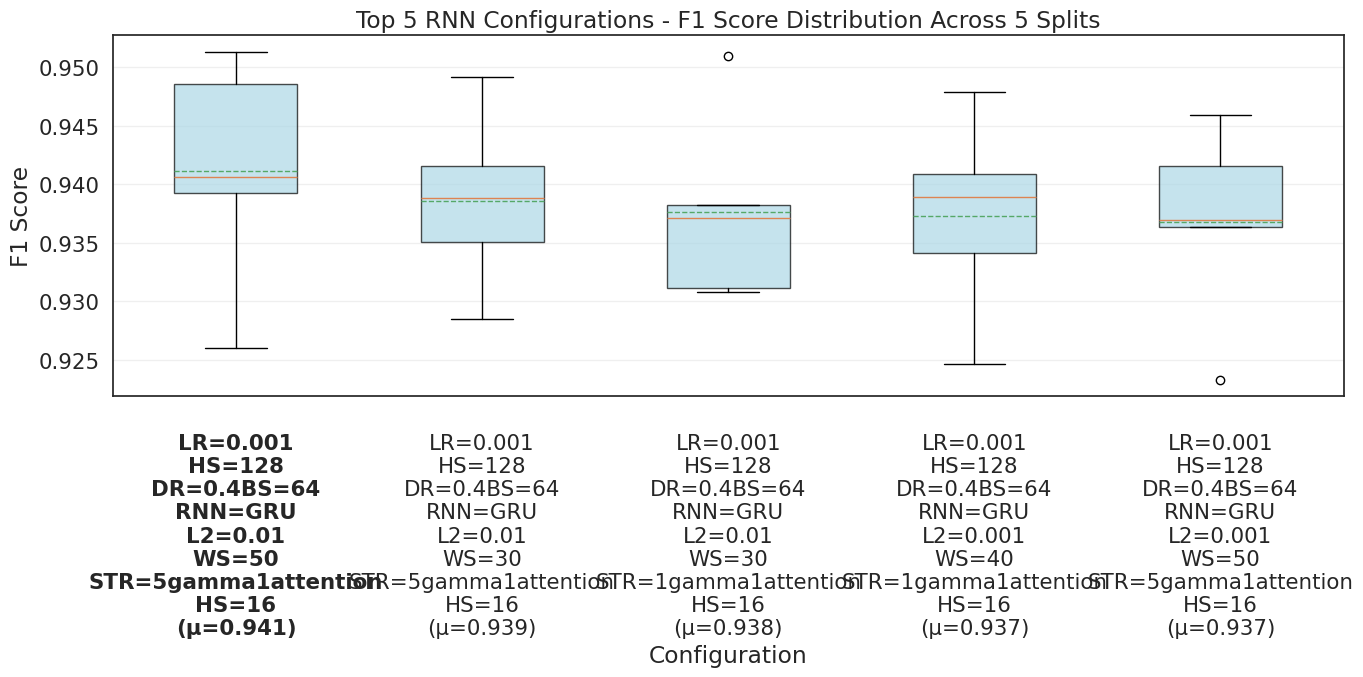

In [ ]:
plot_top_configurations_rnn(results,k_splits=K, top_n=5)

In [ ]:
print(best_config)
final_best_params = {**fixed_params, **best_config}
print(final_best_params)

best_config_str = "_".join([f"{k}_{v}" for k, v in best_config.items()])

{'learning_rate': 0.001, 'hidden_size': 128, 'dropout_rate': 0.4, 'batch_size': 64, 'rnn_type': 'GRU', 'l2_lambda': 0.01, 'window_size': 50, 'stride': 5, 'gamma': 1, 'attention_hidden_size': 16}
{'l1_lambda': 0, 'hidden_layers': 2, 'bidirectional': True, 'stride': 5, 'window_size': 50, 'learning_rate': 0.001, 'hidden_size': 128, 'dropout_rate': 0.4, 'batch_size': 64, 'rnn_type': 'GRU', 'l2_lambda': 0.01, 'gamma': 1, 'attention_hidden_size': 16}


## Inference

Perform test predictions using the best model trained with K-fold cross-validation.  
For each fold, it normalizes the test data using the corresponding training statistics, builds sequences, and creates a DataLoader.  
It loads the trained model for the fold, runs inference, and collects softmax probabilities to make **Soft Voting**.   
All fold predictions are stored in `all_test_targets` to aggregate all the split predictions.


In [ ]:

skf = StratifiedKFold(n_splits=K)
all_test_targets = []    
unique_users_test = X_test['sample_index'].unique()

for split_idx ,(train_users, val_users) in enumerate(skf.split(X=y_train ,y=y_train['label'])):

    # Split the dataset into training, validation, and test sets based on user IDs
    df_train = X_train[X_train['sample_index'].isin(train_users)].copy()
    df_test = X_test.copy()

    # Normalise features using training set statistics
    train_max = df_train[columns].max()
    train_min = df_train[columns].min()

    df_test[columns] = (df_test[columns] - train_min) / (train_max - train_min)
    

    # Build sequences using the existing build_sequences function
    test, _ = build_sequences(df=df_test, y=None, columns=columns, window=final_best_params['window_size'], stride=final_best_params['stride'])
    
    # Create PyTorch datasets
    test_ds = TensorDataset(torch.from_numpy(test))

    # Create data loaders
    test_loader = make_loader(test_ds, batch_size=final_best_params['batch_size'], shuffle=False, drop_last=False)

    if len(test_ds) == 0:
        print(f"WARNING:TEST set for split is empty")
        continue

    model = RecurrentClassifierWithAttention(
            input_size=test.shape[2], # num_features (3)
            hidden_size=final_best_params['hidden_size'],
            num_layers=final_best_params['hidden_layers'],
            num_classes=num_classes,
            dropout_rate=final_best_params['dropout_rate'],
            bidirectional=final_best_params['bidirectional'],
            rnn_type=final_best_params['rnn_type'],
            attention_hidden_size=final_best_params['attention_hidden_size']
        ).to(device)

    # Load the model weights for this specific split and config ---
    model_path = f"models/Attention/{best_config_str}/split_{split_idx}_model.pt"               ##FOLDER


    try:
        model.load_state_dict(torch.load(model_path, map_location=device))
    except FileNotFoundError:
        print(f"  ERROR: Model file not found at {model_path}")


    model.eval() # Set model to evaluation mode

    # Run predictions
    split_test_preds = []
    with torch.no_grad(): # Disable gradient computation for inference
        for xb in test_loader:
            xb = xb[0]
            xb = xb.to(device)
            logits = model(xb)
            
            # Soft Voting
            probs = torch.softmax(logits, dim= 1).cpu().numpy()
            split_test_preds.append(probs)
            
            # Hard voting
            # preds = logits.argmax(dim=1).cpu().numpy()
            # split_test_preds.append(preds)

    split_test_preds = np.concatenate(split_test_preds)
    
    # Merge prediction for the single pirate
    numWindPirate = split_test_preds.shape[0] // 1324
    block_pred = split_test_preds.reshape(1324, numWindPirate, 3)
    prob_per_pirate = block_pred.mean(axis=1)  

    all_test_targets.append(prob_per_pirate)

In [ ]:

# Hard Voting
# preds = np.vstack(all_test_targets)
# # Majority vote 
# final_pred = mode(preds, axis=0, keepdims=False).mode
# print(np.unique(final_pred, return_counts=True))

# Soft Voting
preds = np.array(all_test_targets)
avg_prob = np.mean(preds,axis=0)
final_pred = np.argmax(avg_prob, axis=1)

print(final_pred.size)

label_map = {0: 'no_pain', 1: 'low_pain', 2: 'high_pain'}
final_predictions_labels = pd.Series(final_pred).map(label_map)
unique_users_test_formatted = [str(num).zfill(3) for num in unique_users_test]


# Create a DataFrame with the specified columns
submission_df = pd.DataFrame({
    'sample_index': unique_users_test_formatted,
    'label': final_predictions_labels
})

# Display the first few rows of the submission DataFrame
display(submission_df.head())

# Save the DataFrame to a CSV file
submission_df.to_csv(f'submission{best_config_str}_SOFT.csv', index=False)

1324


,sample_index,label
0,000,no_pain
1,001,no_pain
2,002,no_pain
3,003,no_pain
4,004,no_pain
